# iROAS in geo experiments — a ratio-metric case study

A real-world application of the Battey & Edgar lens (see notebook
`01_treatment_effect_critique_tutorial.ipynb`).

**Setting.** Growth marketing runs in every geo-unit (region). The treatment
policy *negativizes* the budget in treated geos: marketing cost drops
multiplicatively — routinely by 50%, sometimes by **−99%**. The estimand is

$$\mathrm{iROAS} = \frac{\text{incremental revenue}}{\text{incremental cost}}
= \frac{\Delta R}{\Delta C},$$

a **ratio metric**. Practitioners disagree on how to average it across geos:

1. **average of per-geo ratios** — $\frac{1}{n}\sum_i \Delta R_i / \Delta C_i$
   (the eq.-3.1 analog: a unit-level model-free average);
2. **ratio of aggregates** — $\sum_i \Delta R_i / \sum_i \Delta C_i$
   (the standard geo-experiment estimator);
3. **trimmed ratio** — (2) after trimming geos with extreme per-geo ratios;
4. **WLS regression** — $\Delta R_i$ on $\Delta C_i$ through the origin,
   weighted by the known noise structure (the model-based route).

We simulate under the same *fictitious idealisation* as the paper (both
potential outcomes observable per geo), then relax it with an actual
randomized design at the end.

Throughout we use **n = 30 geo-units** — the realistic scale when your geos are regions across a continent (a LATAM-wide footprint, say) rather than hundreds of city-level DMAs. Small, heavy-tailed samples sharpen every pathology below.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from logic.simulation_engine import (
    bias_coverage_summary,
    run_scenarios,
    run_study,
)
from logic.iroas_models import (
    GEO_POPULATIONS,
    GeoiROASModel,
    iroas_inference,
    randomize_assignment,
    randomized_iroas,
)
from logic.likelihoods import fit_size_interaction
from logic.treatment_effect_plots import (
    plot_estimate_stability,
    plot_population_sensitivity,
    plot_geo_ratio_diagnostics,
)

SEED = 20261010
N_GEOS = 30   # realistic scale: regions across LATAM
N_REPS = 300
RHO = 3.0  # true iROAS: each incremental $1 of spend returns $3 of revenue

## 1. The data-generating process

Per geo $i$ with size $\gamma_i$ (heavy-tailed, Zipf-like — a few huge
regions, many tiny ones):

- baseline cost $C_i(0) \propto \gamma_i$ (spend scales with size);
- treated cost $C_i(1) = \kappa \, C_i(0)$ with $\kappa \in (0,1]$ —
  $\kappa = 0.01$ is a −99% negativization. Note this intervention is
  **multiplicative on cost**: a scale-family action, i.e. example 2's
  structure, with stable effect $\log\kappa$ on the log-cost scale;
- revenue $R_i(t) = \text{organic}_i + \rho_i\,C_i(t) + \varepsilon$, with
  noise scale $\sigma_{\text{floor}} + \sigma_r \gamma_i$. The **floor**
  is measurement noise that does *not* shrink with geo size — the realistic
  ingredient that makes tiny geos dangerous for per-geo ratios.

First look: per-geo ratios $\Delta R_i / \Delta C_i$ against geo size, for an
extreme (−99%) and a mild (−5%) negativization.

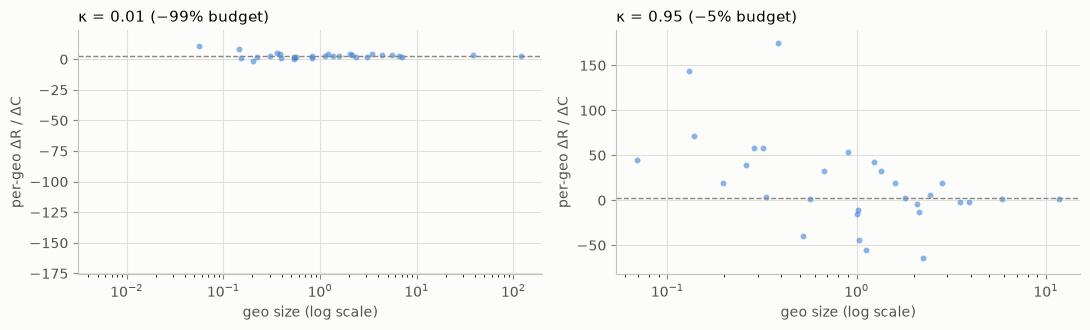

In [2]:
rng = np.random.default_rng(SEED)
deep = GeoiROASModel(GEO_POPULATIONS["zipf_like"], rho0=RHO, kappa=0.01)
mild = GeoiROASModel(GEO_POPULATIONS["zipf_like"], rho0=RHO, kappa=0.95)

d_deep = deep.draw(n=N_GEOS, n_reps=1, rng=rng)
d_mild = mild.draw(n=N_GEOS, n_reps=1, rng=rng)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), facecolor="#fcfcfb")
for ax, d, label in [(axes[0], d_deep, "κ = 0.01 (−99% budget)"),
                     (axes[1], d_mild, "κ = 0.95 (−5% budget)")]:
    plot_geo_ratio_diagnostics(
        d.gamma[0], (d.revenue1 - d.revenue0)[0], (d.cost1 - d.cost0)[0],
        true_value=RHO, title=label, ax=ax,
    )
fig.tight_layout()
plt.show()

**What to look at:** with a deep budget cut (left) the incremental cost is
large in every geo, so per-geo ratios hug the true iROAS — only the tiniest
geos scatter. With a mild cut (right), $\Delta C_i \approx 0$ everywhere and
per-geo ratios explode across the board.

> **Counter-intuitive but important:** the *extreme* −99% negativization is
> the **well-conditioned** case (big denominators). It is *mild* budget
> changes that make per-geo iROAS ratios blow up.

## 2. World (a): one true iROAS exists (constant ρ)

Every geo has the same $\rho_i \equiv 3$. All four estimators target it —
the question is *how reliably*.

In [3]:
df_a = run_study(deep, n=N_GEOS, n_reps=N_REPS, seed=SEED + 1)
df_a.groupby("estimator")["estimate"].agg(
    ["mean", "std", lambda s: s.quantile(0.05), lambda s: s.quantile(0.95)]
).set_axis(["mean", "std", "q05", "q95"], axis=1).round(3)

,mean,std,q05,q95
estimator,,,,
avg_of_geo_ratios,2.888,1.333,1.198,4.400
ratio_of_aggregates,2.995,0.285,2.536,3.429
trimmed_ratio,2.991,0.287,2.532,3.428
wls_regression,3.001,0.228,2.615,3.382


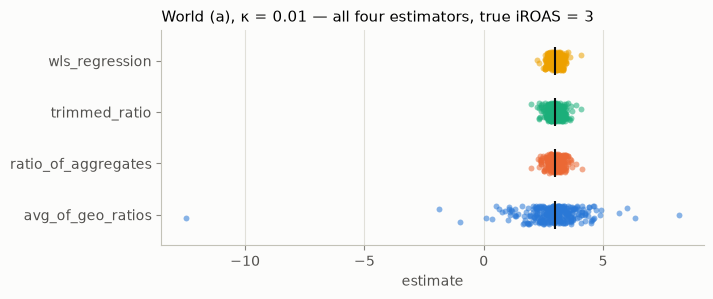

In [4]:
plot_estimate_stability(
    df_a, title="World (a), κ = 0.01 — all four estimators, true iROAS = 3"
)
plt.show()

### Bias and coverage, world (a)

Spread alone can mislead — a tight estimator with a broken confidence
interval is worse than a loose one with an honest interval. So we attach to
each estimator the interval a practitioner would actually report:

- **avg_of_geo_ratios** — plain i.i.d. SE of a mean: $sd(r_i)/\sqrt{n}$;
- **ratio_of_aggregates** — delta-method (linearization) SE of a ratio
  estimator;
- **trimmed_ratio** — same linearization on the kept geos (conditional on the
  trim, as in common practice);
- **wls_regression** — heteroskedasticity-robust (HC1) sandwich SE.

**Bias** = mean estimate − truth across replications; **coverage** = share of
replications whose 95% interval contains the truth (nominal: 0.95).

In [5]:
data_a = deep.draw(n=N_GEOS, n_reps=N_REPS,
                   rng=np.random.default_rng(SEED + 1))
inf_a = iroas_inference(deep, data_a)
bias_coverage_summary(inf_a).round(3)

,true_value,mean,bias,rel_bias_pct,emp_sd,mean_se,coverage
estimator,,,,,,,
avg_of_geo_ratios,3.0,2.888,-0.112,-3.739,1.333,0.860,0.977
ratio_of_aggregates,3.0,2.995,-0.005,-0.183,0.285,0.230,0.850
trimmed_ratio,3.0,2.991,-0.009,-0.304,0.287,0.228,0.843
wls_regression,3.0,3.001,0.001,0.043,0.228,0.218,0.930


**Read-out:** biases stay negligible for the aggregate and regression
estimators, and the per-geo average is roughly unbiased but wild
(replication SD ≈ 1.3 — about 6× the WLS). The new wrinkle at n = 30: the
textbook delta-method interval of the (trimmed) aggregate ratio **already
undercovers** (≈ 0.85 vs a nominal 0.95) — with 30 heavy-tailed geos, a
handful of giant regions dominate the sums and the linearization SE is
optimistic. The model-based WLS is simultaneously the tightest *and* the
most honest (coverage 0.93). At this sample size, validity is no longer
free.

With −99% negativization everything looks fine (ratios well-conditioned). Now
sweep the negativization depth.

## 3. Sweep: how deep does the budget cut go?

$\kappa \in \{0.01, 0.3, 0.7, 0.95\}$ — from −99% down to a −5% nudge.

In [6]:
sweep = {
    f"κ = {k} (−{round((1 - k) * 100)}%)": GeoiROASModel(
        GEO_POPULATIONS["zipf_like"], rho0=RHO, kappa=k)
    for k in (0.01, 0.3, 0.7, 0.95)
}
sc_sweep = run_scenarios(sweep, n=N_GEOS, n_reps=N_REPS, seed=SEED + 2)
sc_sweep.groupby(["scenario", "estimator"])["estimate"].agg(
    ["mean", "std"]).round(2)

mean    std
scenario        estimator                       
κ = 0.01 (−99%) avg_of_geo_ratios    3.08   1.27
                ratio_of_aggregates  3.02   0.31
                trimmed_ratio        3.02   0.31
                wls_regression       3.00   0.23
κ = 0.3 (−70%)  avg_of_geo_ratios    2.91   1.68
                ratio_of_aggregates  2.99   0.42
                trimmed_ratio        2.99   0.43
                wls_regression       3.00   0.31
κ = 0.7 (−30%)  avg_of_geo_ratios    2.79   3.59
                ratio_of_aggregates  3.08   1.01
                trimmed_ratio        3.09   1.00
                wls_regression       3.00   0.74
κ = 0.95 (−5%)  avg_of_geo_ratios    4.35  31.18
                ratio_of_aggregates  2.57   5.85
                trimmed_ratio        2.59   5.86
                wls_regression       2.77   4.43

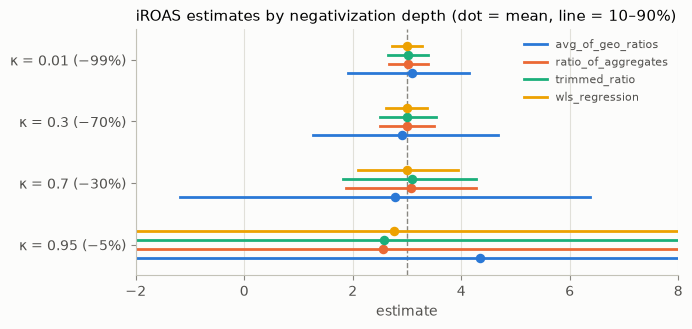

In [7]:
plot_population_sensitivity(
    sc_sweep, true_value=RHO, quantiles=(0.1, 0.9),
    title="iROAS estimates by negativization depth (dot = mean, line = 10–90%)",
)
plt.xlim(-2, 8)
plt.show()

### Bias and coverage across the sweep

Does the mild-cut explosion break the *intervals* too, or "only" widen
them?

In [8]:
parent = np.random.default_rng(SEED + 10)
frames = []
for label, m in sweep.items():
    d = m.draw(n=N_GEOS, n_reps=N_REPS, rng=parent.spawn(1)[0])
    inf = iroas_inference(m, d)
    inf["scenario"] = label
    frames.append(inf)
inf_sweep = pd.concat(frames, ignore_index=True)
bias_coverage_summary(
    inf_sweep, group_cols=("scenario", "estimator")
)[["bias", "emp_sd", "mean_se", "coverage"]].round(3)

bias  emp_sd  mean_se  coverage
scenario        estimator                                            
κ = 0.01 (−99%) avg_of_geo_ratios    0.091   1.138    0.925     0.970
                ratio_of_aggregates -0.017   0.283    0.231     0.850
                trimmed_ratio       -0.023   0.284    0.227     0.827
                wls_regression      -0.008   0.210    0.217     0.950
κ = 0.3 (−70%)  avg_of_geo_ratios    0.010   1.533    1.199     0.957
                ratio_of_aggregates -0.028   0.434    0.329     0.823
                trimmed_ratio       -0.023   0.435    0.326     0.833
                wls_regression       0.004   0.314    0.303     0.933
κ = 0.7 (−30%)  avg_of_geo_ratios   -0.300   5.515    3.219     0.940
                ratio_of_aggregates  0.118   1.051    0.788     0.860
                trimmed_ratio        0.122   1.066    0.775     0.827
                wls_regression       0.043   0.808    0.744     0.920
κ = 0.95 (−5%)  avg_of_geo_ratios   -0.847  21.657   17.161     0.967
                ratio_of_aggregates -0.484   6.019    4.483     0.840
                trimmed_ratio       -0.427   6.085    4.403     0.823
                wls_regression      -0.361   4.340    4.273     0.947

**Read-out:** two separate pathologies, and the table separates them
cleanly. *Width:* the mean SE grows ≈ 19× from κ = 0.01 to κ = 0.95 for
every estimator (≈ 0.93 → ≈ 17 for the per-geo average, ≈ 0.22 → ≈ 4.3 for
WLS) — matching the 1/(1−κ) leverage prediction of 0.99/0.05 ≈ 19.8×.
*Validity:* only the model-based WLS keeps near-nominal coverage at every
depth (0.92–0.95); the aggregate-ratio intervals run ≈ 10 points hot
(0.82–0.86) at this sample size *regardless of depth*. And with
heavy-tailed per-geo ratios at κ = 0.95, even the Monte-Carlo mean of
`avg_of_geo_ratios` is unstable — its apparent bias there is within its own
replication noise, which is itself the warning.

**Takeaways.**

- `avg_of_geo_ratios` degrades first and worst as cuts get milder — by
  κ = 0.95 its replication spread is an order of magnitude wider than WLS.
  This is **example 4's "γ near zero" pathology** wearing ratio-metric
  clothes: unit-level model-free averages are at the mercy of
  badly-conditioned units.
- `wls_regression` — the model-based estimator, which *uses* the known noise
  structure — stays the most stable at every depth.
- Trimming helps the tails but cannot repair a mild intervention: if
  $\Delta C \approx 0$ in every geo, no reweighting of geos fixes the
  denominator.
- **Design implication:** if you must negativize to measure iROAS, negativize
  *hard*. Statistical conditioning and business caution pull in opposite
  directions here, and pretending otherwise biases nothing but your variance.
- **Coverage note:** at n = 30, only the WLS intervals stay near-nominal
  across the sweep; the aggregate ratio's standard delta-method intervals
  run ≈ 10 points below nominal at *every* depth, and mild cuts add the
  width explosion on top. At realistic region counts, validity *and*
  information both favor the model-based route.

## 4. World (b): no single iROAS exists (heterogeneous ρᵢ)

Now the marginal ROAS varies with geo size:
$\rho_i = \rho_0 (\gamma_i/\mathrm{med}\,\gamma)^{\delta}$ with
$\delta = 0.3$ — big markets convert ad spend better. Which number is "the"
iROAS?

- `avg_of_geo_ratios` → the **unweighted** mean of $\rho_i$;
- `ratio_of_aggregates` → the **cost-weighted** mean of $\rho_i$
  (dominated by the big geos).

Both are "correct"… for *different estimands* — and both move when the
geo-size population changes. This is **examples 4–5's sample-dependence**,
restated for ratio metrics.

In [9]:
DELTA_SIZE = 0.3
het = {
    pop: GeoiROASModel(dist, rho0=RHO, kappa=0.01,
                       rho_size_exponent=DELTA_SIZE)
    for pop, dist in GEO_POPULATIONS.items()
}
sc_b = run_scenarios(het, n=N_GEOS, n_reps=N_REPS, seed=SEED + 3)

# Each estimator's own large-n target, computed from one huge draw
big = het["zipf_like"].draw(n=200_000, n_reps=1,
                            rng=np.random.default_rng(SEED + 4))
dc = (big.cost1 - big.cost0)[0]
targets = pd.Series({
    "unweighted mean of rho_i": big.rho[0].mean(),
    "cost-weighted mean of rho_i": np.sum(big.rho[0] * dc) / np.sum(dc),
    "rho0 (median geo)": RHO,
}).round(3)
print(targets)
sc_b.groupby(["scenario", "estimator"])["estimate"].mean().unstack(
    "scenario").round(3)

unweighted mean of rho_i       3.317
cost-weighted mean of rho_i    6.343
rho0 (median geo)              3.000
dtype: float64


scenario,homogeneous,zipf_like
estimator,,
avg_of_geo_ratios,3.001,3.289
ratio_of_aggregates,3.040,5.841
trimmed_ratio,3.032,5.017
wls_regression,3.041,4.619


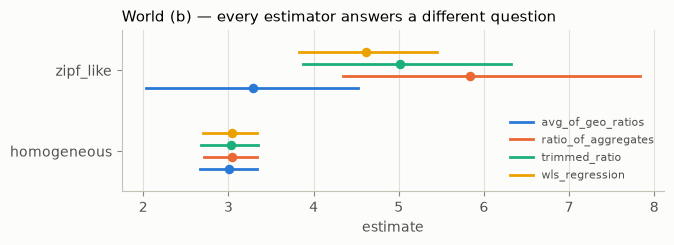

In [10]:
plot_population_sensitivity(
    sc_b, quantiles=(0.1, 0.9),
    title="World (b) — every estimator answers a different question",
)
plt.show()

### "Unbiased" — for which target?

In world (b) there is no single truth, so *bias* and *coverage* are undefined
until you pick a target. So let's give every estimator its best shot: measure
each against **its own** large-n limit (computed from the 200k-geo draw
above). Then, as a cross-check, ask how often the per-geo-ratio interval
covers the *cost-weighted* target — the number the aggregate-ratio camp
reports.

In [11]:
from logic.likelihoods import trimmed_ratio, wls_through_origin

# Each estimator's own large-n target, from the big draw of cell above
dr_big = (big.revenue1 - big.revenue0)
dc_big = (big.cost1 - big.cost0)
w_big = 1.0 / het["zipf_like"].noise_scale(big.gamma) ** 2
own_targets = {
    "avg_of_geo_ratios": float(np.mean((dr_big / dc_big)[0])),
    "ratio_of_aggregates": float(dr_big.sum() / dc_big.sum()),
    "trimmed_ratio": float(trimmed_ratio(dr_big, dc_big, 0.05)[0]),
    "wls_regression": float(
        wls_through_origin(dr_big, dc_big, w_big)[0]),
}
print("own large-n targets:",
      {k: round(v, 3) for k, v in own_targets.items()})

data_b2 = het["zipf_like"].draw(n=N_GEOS, n_reps=N_REPS,
                                rng=np.random.default_rng(SEED + 11))
inf_b = iroas_inference(het["zipf_like"], data_b2)
inf_b["true_value"] = inf_b["estimator"].map(own_targets)
print(bias_coverage_summary(inf_b).round(3))

# Cross-check: does the per-geo-ratio interval ever cover the
# cost-weighted answer?
avg = inf_b[inf_b.estimator == "avg_of_geo_ratios"]
target_cw = own_targets["ratio_of_aggregates"]
cross = ((avg["estimate"] - 1.96 * avg["se"] <= target_cw)
         & (target_cw <= avg["estimate"] + 1.96 * avg["se"])).mean()
print(f"\navg_of_geo_ratios CI covers the cost-weighted "
      f"target {target_cw:.2f}: {cross:.1%} of replications")

own large-n targets: {'avg_of_geo_ratios': 3.319, 'ratio_of_aggregates': 6.336, 'trimmed_ratio': 5.118, 'wls_regression': 4.597}
                     true_value   mean   bias  rel_bias_pct  emp_sd  mean_se  \
estimator                                                                      
avg_of_geo_ratios         3.319  3.303 -0.016        -0.493   1.230    0.940   
ratio_of_aggregates       6.336  5.834 -0.502        -7.923   1.615    0.706   
trimmed_ratio             5.118  4.989 -0.129        -2.527   1.089    0.486   
wls_regression            4.597  4.624  0.027         0.591   0.700    0.481   

                     coverage  
estimator                      
avg_of_geo_ratios       0.963  
ratio_of_aggregates     0.510  
trimmed_ratio           0.613  
wls_regression          0.813  

avg_of_geo_ratios CI covers the cost-weighted target 6.34: 11.3% of replications


Two lessons, and both strengthen the estimand argument:

1. **Each estimator is (nearly) unbiased only for its own estimand.** The
   per-geo-ratio average covers *its* target at the nominal rate — and
   covers the cost-weighted target in about one replication in nine (11%;
   at n = 200 geos, where intervals are tighter, this drops to ~1%). Two teams can both run
   "unbiased, 95%-covered" analyses of the same experiment and exclude each
   other's answer with confidence. The disagreement is in the estimand, not
   the statistics.
2. **Under heavy-tailed geo sizes, the cost-weighted estimand is barely
   estimable at n = 30.** `ratio_of_aggregates` lands ≈ 8% *below* its own
   large-n target on average and covers it in only ≈ 51% of replications
   (vs a nominal 95%): the target is dominated by tail geos that a 30-geo
   sample rarely represents well, and the linearization SE understates on
   top. The population-dependence that defines world (b) also makes the
   model-free targets hard to even pin down.

**What happened:** under the heavy-tailed (`zipf_like`) population the
cost-weighted answer (ratio of aggregates) sits far above the unweighted one;
under near-equal geos (`homogeneous`) they collapse together. Change the
population of geos → change "the iROAS", for every model-free estimator. No
reference line is drawn because **there is no single stable target**.

### The model-based resolution: model the interaction

Battey & Edgar's prescription (§5): systematic effect heterogeneity belongs
*in the model*. Fit $\Delta R_i = \rho_0 (\gamma_i/\mathrm{med})^{\delta}
\Delta C_i + \varepsilon$ and recover the stable pair $(\rho_0, \delta)$ —
a description of *how* iROAS varies with size, valid across geo
populations.

In [12]:
data_b = het["zipf_like"].draw(n=N_GEOS, n_reps=100,
                               rng=np.random.default_rng(SEED + 5))
noise = het["zipf_like"].noise_scale(data_b.gamma)
fit = fit_size_interaction(
    data_b.revenue1 - data_b.revenue0,
    data_b.cost1 - data_b.cost0,
    data_b.gamma,
    weights=1.0 / noise**2,
)
pd.DataFrame({
    "rho0_hat": [fit["rho0"].mean(), fit["rho0"].std()],
    "delta_hat": [fit["delta"].mean(), fit["delta"].std()],
}, index=["mean", "std"]).round(3)

,rho0_hat,delta_hat
mean,2.998,0.301
std,0.295,0.049


The pair (ρ₀ ≈ 3, δ ≈ 0.3) is recovered and — unlike every ratio average
above — means the same thing whatever geos the next experiment samples. Any
aggregate a stakeholder wants (unweighted, cost-weighted, for a specific geo
portfolio) can then be *computed* from the fitted model, with the weighting
chosen deliberately rather than inherited silently from an estimator.

## 5. Reality check: an actual randomized design

Drop the idealisation: randomize geos 50/50, observe only one arm per geo, and
estimate iROAS feasibly as treated-minus-control group means
(ΔR̄ / ΔC̄).

In [13]:
model = GeoiROASModel(GEO_POPULATIONS["zipf_like"], rho0=RHO, kappa=0.01)
rng = np.random.default_rng(SEED + 6)
data = model.draw(n=N_GEOS, n_reps=N_REPS, rng=rng)
obs = randomize_assignment(data, p_treated=0.5, rng=rng)
feasible = randomized_iroas(obs["revenue"], obs["cost"], obs["treated"])

ideal = run_study(model, n=N_GEOS, n_reps=N_REPS, seed=SEED + 7)
ideal_roa = ideal[ideal.estimator == "ratio_of_aggregates"]["estimate"]
rows = {}
for label, x in [("randomized diff-in-means ratio", feasible),
                 ("idealised ratio_of_aggregates", ideal_roa)]:
    x = np.asarray(x, dtype=float)
    rows[label] = {
        "mean": np.nanmean(x),
        "median": np.nanmedian(x),
        "q05": np.nanquantile(x, 0.05),
        "q95": np.nanquantile(x, 0.95),
    }
pd.DataFrame(rows).T.round(3)

,mean,median,q05,q95
randomized diff-in-means ratio,0.790,3.006,-12.566,6.834
idealised ratio_of_aggregates,2.972,2.993,2.501,3.392


At 30 geos, naive 50/50 randomization is close to hopeless: the estimate's
*median* sits on the truth (≈ 3.0), but its 5–95% range spans **−12.6 to
+6.8** and its mean is meaningless — chance imbalance between 15 treated and
15 control heavy-tailed geos routinely puts the incremental-cost denominator
near zero, where the ratio has no usable moments. (This is exactly why
practical geo-experiment methods at this scale lean on matched pairs, size
stratification, pre-period covariate adjustment, or synthetic controls — all
*model-based* repairs, and all outside this notebook's scope.) The estimand
lessons above are unchanged: the randomized design targets the
*cost-weighted* aggregate, now with crushing noise on top. At a continental
region count, design care is not optional.

## 6. Linking back to Battey & Edgar

| Case-study phenomenon | Paper counterpart |
|---|---|
| Budget negativization is multiplicative on cost: stable effect log κ on the log scale | **Example 2** — scale-family actions have a stable transformed effect |
| Tiny geos (or mild cuts) make per-geo ratios explode | **Example 4** — units with γ near zero dominate unit-level model-free averages |
| "Which average is THE iROAS?" has no answer under heterogeneity; every estimator shifts with the geo population | **Examples 4–5** — model-free effects are sample-dependent when stability conditions fail |
| Fit (ρ₀, δ) via an explicit size interaction; compute any aggregate afterwards | **§5** — heterogeneity belongs in the model as interactions, keeping parameters stable |

## 7. Practical guidance

1. **Declare the estimand first.** "Unbiased iROAS" is undefined until you say
   *which* iROAS: unweighted-by-geo, cost-weighted, or a model parameter.
   Under heterogeneity these genuinely differ.
2. **Never average per-geo ratios** when incremental cost can be near zero in
   any geo — mild interventions and tiny geos both do it. If you must, trim —
   and report that the trimming fraction is now part of the estimand.
3. **Ratio of aggregates** is defensible and simple, but understand it is
   cost-weighted: your biggest markets *are* the estimate.
4. **The model-based route** (regression with the right weights, interactions
   for systematic heterogeneity) is the only one whose answer transfers to a
   different portfolio of geos — the paper's central claim, replayed in
   production clothes.
5. **Deep negativizations are statistically kind.** A −99% cut gives large,
   well-conditioned denominators; a −5% nudge gives an experiment that mostly
   measures noise.
6. **"Unbiased" is a cheap word.** In world (a) all four estimators were
   unbiased with valid intervals and still differed ~5× in interval width;
   in world (b) each was unbiased only *for its own estimand*. The questions
   that discriminate are "unbiased **for what**?" and "**how wide** is the
   honest interval?" — never "is it unbiased?" alone.